# Brain Tumor Segmentation — VGG19-U-Net (PyTorch port)

This is a PyTorch port of the uploaded TensorFlow/Keras notebook (the one whose "Create Model" cell builds a from-scratch SegFormer (MiT-B0) in `tf.keras`, despite the notebook's title/loss comments still referring to VGG19). This port mirrors the approach already validated in the earlier SegFormer PyTorch port: a pretrained SegFormer (MiT) encoder from Hugging Face `transformers`, paired with a U-Net-style decoder, since a from-scratch untrained transformer encoder has no ImageNet weights to start from and would need far more data/epochs to converge than this dataset provides.

Notes on the port, beyond what the earlier SegFormer port already covered:

- **Boundary-aware loss.** This notebook's "Training Model" section adds a `boundary_loss` (Sobel-edge L2 distance between predicted and ground-truth mask edges) on top of `focal_tversky`, combined as `combined_loss = focal_tversky + boundary_weight * boundary_loss`. `tf.nn.conv2d(..., padding='SAME')` with a 3×3 kernel and stride 1 is ported to `torch.nn.functional.conv2d(..., padding=1)` — mathematically identical, so the Sobel filters carry over unchanged.
- **Training loop.** Backprop now runs on `combined_loss` (matching `model.compile(loss=combined_loss, metrics=[tversky, boundary_loss])`), and the per-epoch history also tracks `boundary_loss` / `val_boundary_loss` alongside `loss`/`tversky`.
- **Quantitative evaluation.** The Dice / IoU / pixel-accuracy / precision-recall section at the end is framework-agnostic (plain NumPy over the already-computed predictions), so it carries over unchanged.

Everything else — data loading, the `Dataset`/`DataLoader`, the SegFormer+U-Net architecture, and the manual training loop scaffolding (LR scheduling, checkpointing, early stopping) — follows the earlier PyTorch port.

# Import libraries

In [9]:
import os
import glob
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from skimage import io
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision

from warnings import filterwarnings
filterwarnings('ignore')

print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)

torch: 2.10.0+cu128
torchvision: 0.25.0+cu128


In [10]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)
if device.type == 'cuda':
    print(torch.cuda.get_device_name(0))

Using device: cuda
Tesla T4


# Prepare dataset

In [11]:
data = pd.read_csv('../input/lgg-mri-segmentation/kaggle_3m/data.csv')
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Patient                    110 non-null    object 
 1   RNASeqCluster              92 non-null     float64
 2   MethylationCluster         109 non-null    float64
 3   miRNACluster               110 non-null    int64  
 4   CNCluster                  108 non-null    float64
 5   RPPACluster                98 non-null     float64
 6   OncosignCluster            105 non-null    float64
 7   COCCluster                 110 non-null    int64  
 8   histological_type          109 non-null    float64
 9   neoplasm_histologic_grade  109 non-null    float64
 10  tumor_tissue_site          109 non-null    float64
 11  laterality                 109 non-null    float64
 12  tumor_location             109 non-null    float64
 13  gender                     109 non-null    float64

In [12]:
data.head(10)

,Patient,RNASeqCluster,MethylationCluster,miRNACluster,CNCluster,RPPACluster,OncosignCluster,COCCluster,histological_type,neoplasm_histologic_grade,tumor_tissue_site,laterality,tumor_location,gender,age_at_initial_pathologic,race,ethnicity,death01
0,TCGA_CS_4941,2.0,4.0,2,2.0,NaN,3.0,2,1.0,2.0,1.0,3.0,2.0,2.0,67.0,3.0,2.0,1.0
1,TCGA_CS_4942,1.0,5.0,2,1.0,1.0,2.0,1,1.0,2.0,1.0,3.0,2.0,1.0,44.0,2.0,NaN,1.0
2,TCGA_CS_4943,1.0,5.0,2,1.0,2.0,2.0,1,1.0,2.0,1.0,1.0,2.0,2.0,37.0,3.0,NaN,0.0
3,TCGA_CS_4944,NaN,5.0,2,1.0,2.0,1.0,1,1.0,1.0,1.0,3.0,6.0,2.0,50.0,3.0,NaN,0.0
4,TCGA_CS_5393,4.0,5.0,2,1.0,2.0,3.0,1,1.0,2.0,1.0,1.0,6.0,2.0,39.0,3.0,NaN,0.0
5,TCGA_CS_5395,2.0,4.0,2,2.0,NaN,3.0,2,3.0,1.0,1.0,3.0,5.0,2.0,43.0,2.0,NaN,1.0
6,TCGA_CS_5396,3.0,3.0,2,3.0,2.0,2.0,3,3.0,2.0,1.0,3.0,2.0,1.0,53.0,3.0,2.0,0.0
7,TCGA_CS_5397,NaN,4.0,1,2.0,3.0,3.0,2,1.0,2.0,1.0,1.0,6.0,1.0,54.0,3.0,2.0,1.0
8,TCGA_CS_6186,2.0,4.0,1,2.0,1.0,3.0,2,2.0,2.0,1.0,3.0,2.0,2.0,58.0,3.0,2.0,1.0
9,TCGA_CS_6188,2.0,4.0,3,2.0,3.0,3.0,2,1.0,2.0,1.0,3.0,6.0,2.0,48.0,3.0,2.0,0.0


In [13]:
data_map = []
for sub_dir_path in glob.glob("/kaggle/input/lgg-mri-segmentation/kaggle_3m/" + "*"):
    try:
        dir_name = sub_dir_path.split('/')[-1]
        for filename in os.listdir(sub_dir_path):
            image_path = sub_dir_path + '/' + filename
            data_map.extend([dir_name, image_path])
    except Exception as e:
        print(e)

[Errno 20] Not a directory: '/kaggle/input/lgg-mri-segmentation/kaggle_3m/README.md'
[Errno 20] Not a directory: '/kaggle/input/lgg-mri-segmentation/kaggle_3m/data.csv'


In [14]:
df = pd.DataFrame({"patient_id": data_map[::2],
                    "path": data_map[1::2]})
df.head()

,patient_id,path
0,TCGA_DU_7010_19860307,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...
1,TCGA_DU_7010_19860307,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...
2,TCGA_DU_7010_19860307,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...
3,TCGA_DU_7010_19860307,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...
4,TCGA_DU_7010_19860307,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...


In [15]:
df_imgs = df[~df['path'].str.contains("mask")]  # no mask
df_masks = df[df['path'].str.contains("mask")]   # mask

# File path line length for sorting
BASE_LEN = 89     # len(/kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_6404_19850629/TCGA_DU_6404_19850629_ <-!!!43.tif)
END_IMG_LEN = 4    # len(...43 !!!->.tif)
END_MASK_LEN = 9   # len(...43 !!!->_mask.tif)

imgs = sorted(df_imgs["path"].values, key=lambda x: int(x[BASE_LEN:-END_IMG_LEN]))
masks = sorted(df_masks["path"].values, key=lambda x: int(x[BASE_LEN:-END_MASK_LEN]))

idx = random.randint(0, len(imgs) - 1)
print("Path to the Image:", imgs[idx], "\nPath to the Mask:", masks[idx])

Path to the Image: /kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_5851_19950428/TCGA_DU_5851_19950428_30.tif 
Path to the Mask: /kaggle/input/lgg-mri-segmentation/kaggle_3m/TCGA_DU_5851_19950428/TCGA_DU_5851_19950428_30_mask.tif


In [16]:
# Final dataframe
brain_df = pd.DataFrame({"patient_id": df_imgs.patient_id.values,
                          "image_path": imgs,
                          "mask_path": masks})

def pos_neg_diagnosis(mask_path):
    value = np.max(cv2.imread(mask_path))
    return 1 if value > 0 else 0

brain_df['mask'] = brain_df['mask_path'].apply(lambda x: pos_neg_diagnosis(x))
brain_df

,patient_id,image_path,mask_path,mask
0,TCGA_DU_7010_19860307,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0
1,TCGA_DU_7010_19860307,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0
2,TCGA_DU_7010_19860307,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0
3,TCGA_DU_7010_19860307,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0
4,TCGA_DU_7010_19860307,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0
...,...,...,...,...
3924,TCGA_DU_7306_19930512,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0
3925,TCGA_DU_7306_19930512,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0
3926,TCGA_DU_7306_19930512,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0
3927,TCGA_DU_7306_19930512,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0


# Visualization

In [17]:
brain_df['mask'].value_counts()

mask
0    2556
1    1373
Name: count, dtype: int64

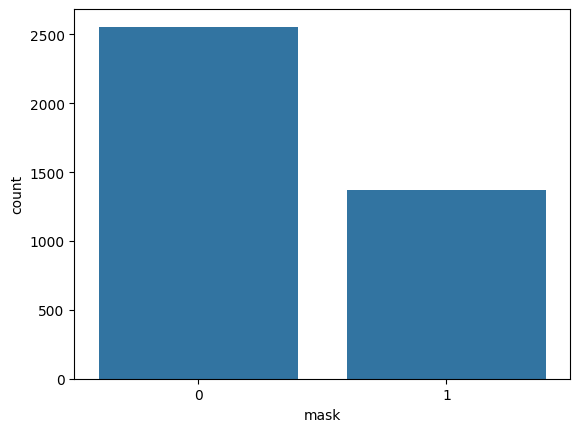

In [18]:
sns.countplot(x=brain_df['mask'])
plt.show()

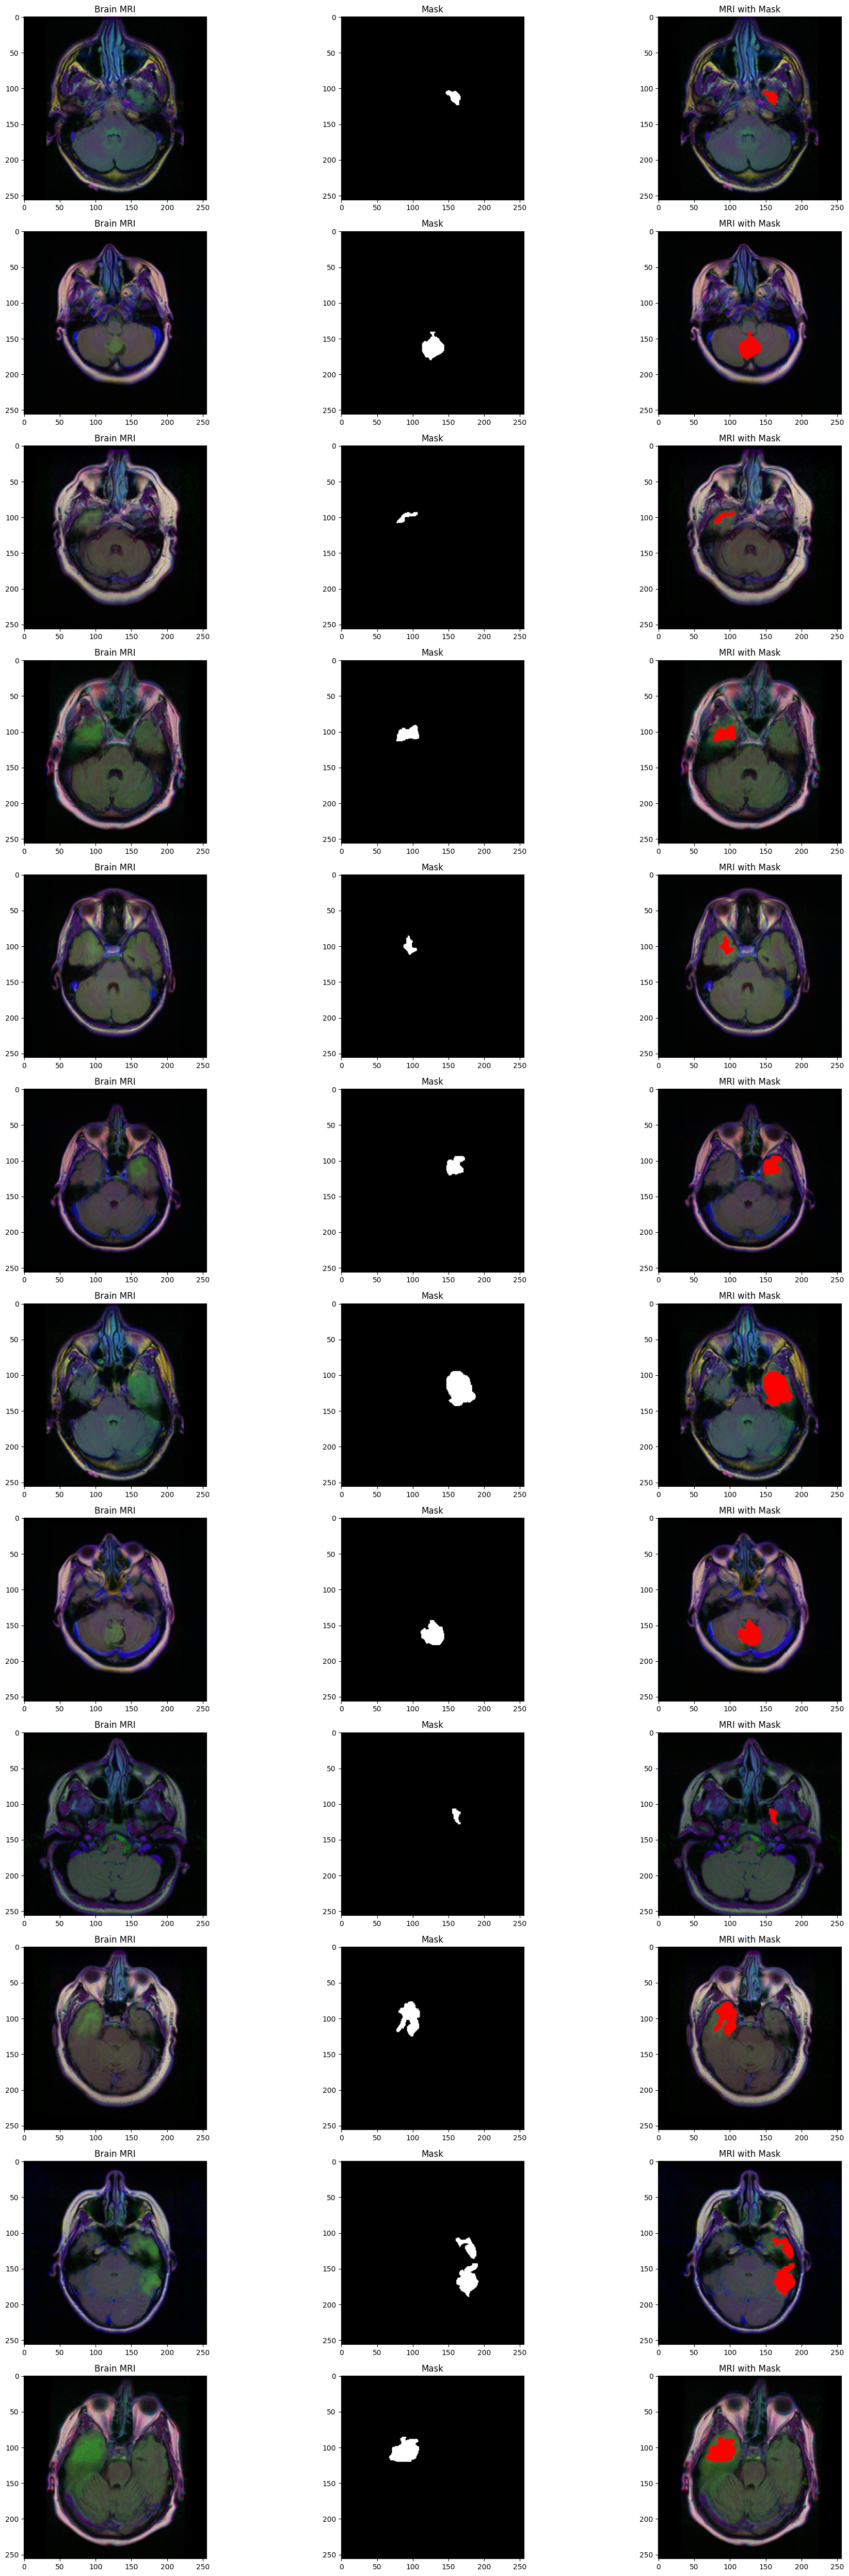

In [19]:
count = 0
i = 0
fig, axs = plt.subplots(12, 3, figsize=(20, 50))
for mask in brain_df['mask']:
    if mask == 1:
        img = io.imread(brain_df.image_path[i])
        axs[count][0].title.set_text("Brain MRI")
        axs[count][0].imshow(img)

        mask_img = io.imread(brain_df.mask_path[i])
        axs[count][1].title.set_text("Mask")
        axs[count][1].imshow(mask_img, cmap='gray')

        img[mask_img == 255] = (255, 0, 0)  # change pixel color at the position of mask
        axs[count][2].title.set_text("MRI with Mask")
        axs[count][2].imshow(img)
        count += 1
    i += 1
    if count == 12:
        break

fig.tight_layout()

# Preprocessing image

In [20]:
brain_df_mask = brain_df
brain_df_mask.shape

(3929, 4)

In [21]:
# creating test, train and val sets
X_train, X_val = train_test_split(brain_df_mask, test_size=0.15, random_state=42)
X_test, X_val = train_test_split(X_val, test_size=0.5, random_state=42)
print("Train size is {}, valid size is {} & test size is {}".format(len(X_train), len(X_val), len(X_test)))

X_train = X_train.reset_index(drop=True)
X_val = X_val.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)

Train size is 3339, valid size is 295 & test size is 295


# Dataset & DataLoader

PyTorch equivalent of the Keras `DataGenerator`. A `Dataset` returns one sample at a time (the `DataLoader` handles batching, shuffling, and dropping the trailing partial batch — the `DataGenerator.__len__` did the same via `floor(len/batch_size)`).

In [22]:
IMG_SIZE = 256


class BrainMRIDataset(Dataset):
    """Loads an MRI slice + mask, resizes, optionally augments, and
    standardises — mirroring the original DataGenerator/__augment logic."""

    def __init__(self, df, img_size=IMG_SIZE, augment=False):
        self.image_paths = df['image_path'].tolist()
        self.mask_paths = df['mask_path'].tolist()
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.image_paths)

    def _augment(self, img, mask):
        # random horizontal flip
        if np.random.rand() < 0.5:
            img = np.fliplr(img)
            mask = np.fliplr(mask)

        # random vertical flip
        if np.random.rand() < 0.5:
            img = np.flipud(img)
            mask = np.flipud(mask)

        # random rotation, same angle applied to image and mask
        if np.random.rand() < 0.5:
            angle = np.random.uniform(-15, 15)
            h, w = img.shape[:2]
            M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
            img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
            mask = cv2.warpAffine(mask, M, (w, h), borderMode=cv2.BORDER_REFLECT, flags=cv2.INTER_NEAREST)

        # random zoom, same scale applied to image and mask
        if np.random.rand() < 0.5:
            scale = np.random.uniform(0.9, 1.1)
            h, w = img.shape[:2]
            M = cv2.getRotationMatrix2D((w / 2, h / 2), 0, scale)
            img = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
            mask = cv2.warpAffine(mask, M, (w, h), borderMode=cv2.BORDER_REFLECT, flags=cv2.INTER_NEAREST)

        # random brightness/contrast jitter - image only, never touch the mask
        if np.random.rand() < 0.5:
            brightness = np.random.uniform(-15, 15)
            contrast = np.random.uniform(0.9, 1.1)
            img = img * contrast + brightness

        return img, mask

    def __getitem__(self, idx):
        img = io.imread(self.image_paths[idx])
        mask = io.imread(self.mask_paths[idx])

        img = cv2.resize(img, (self.img_size, self.img_size))
        img = np.array(img, dtype=np.float64)

        mask = cv2.resize(mask, (self.img_size, self.img_size))
        mask = np.array(mask, dtype=np.float64)

        if self.augment:
            img, mask = self._augment(img, mask)

        # standardise, same as the original generator
        img = (img - img.mean()) / (img.std() + 1e-8)
        mask = (mask - mask.mean()) / (mask.std() + 1e-8)

        mask = np.expand_dims(mask, axis=2)
        mask = (mask > 0).astype(np.float32)

        # HWC -> CHW for PyTorch
        img = torch.from_numpy(img.transpose(2, 0, 1)).float()
        mask = torch.from_numpy(mask.transpose(2, 0, 1)).float()

        return img, mask


BATCH_SIZE = 16

train_dataset = BrainMRIDataset(X_train, augment=True)
val_dataset = BrainMRIDataset(X_val, augment=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=True, num_workers=2)

# Create Model

In [23]:
class ConvBlock(nn.Module):
    """Two Conv-BN-ReLU layers, matching the Keras conv_block helper."""

    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class DecoderBlock(nn.Module):
    """Upsample -> concat with encoder skip -> ConvBlock, matching the
    Keras decoder_block helper (Conv2DTranspose + Concatenate + conv_block)."""

    def __init__(self, in_ch, skip_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.conv = ConvBlock(out_ch + skip_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        if x.shape[-2:] != skip.shape[-2:]:
            x = nn.functional.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, skip], dim=1)
        return self.conv(x)

**Using a pretrained SegFormer encoder.** The uploaded notebook's "Create Model" cell builds a SegFormer (MiT-B0) *from scratch* in `tf.keras`, with no pretrained weights — its own docstring says as much, pointing to Hugging Face's `TFSegformerForSemanticSegmentation` for pretrained weights instead. An untrained transformer encoder has no ImageNet prior to lean on and would need far more data/epochs than this ~a-few-thousand-slice dataset to converge, so this port uses the pretrained `SegformerModel` from `transformers` (validated in the earlier PyTorch port of this notebook's SegFormer variant) rather than reimplementing the from-scratch encoder.

A MiT (Mix Transformer) backbone is hierarchical but only has **4** stages, at strides 4, 8, 16, 32 — unlike VGG19's 5 levels at strides 1, 2, 4, 8, 16. So the decoder below skip-connects the 3 stages it can (strides 32→16→8→4), then adds two plain (skip-free) upsampling stages to get from stride 4 back to the full input resolution.

**Note on the `transformers` version:** SegFormer needs `transformers>=4.12`, but HF made `safetensors` a *required* dependency starting in `4.30`, and `safetensors` has no prebuilt wheel for older Python (3.7-era) environments — so installing `transformers>=4.30` there fails to build and silently leaves the old version in place. The cell below pins `4.29.2`: new enough for SegFormer, old enough to predate the mandatory `safetensors` dependency. If this specific pin ever fails to resolve in your environment, any version in the 4.12–4.29 range should work the same way. And as before: if `transformers` was already imported earlier in this kernel session, **restart the kernel** after installing so the new version actually loads.

In [24]:


import transformers
print("transformers:", transformers.__version__)


from transformers import SegformerModel, SegformerConfig

SEGFORMER_CHECKPOINT = "nvidia/mit-b0"  # smallest MiT backbone, ImageNet-pretrained (encoder only, no seg head)


class SegformerEncoder(nn.Module):
    """Wraps a pretrained SegFormer (MiT) backbone and exposes its 4
    hierarchical stage feature maps (already channels-first, B x C x H x W)
    for use as U-Net skip connections."""

    def __init__(self, checkpoint=SEGFORMER_CHECKPOINT, pretrained=True):
        super().__init__()
        if pretrained:
            self.backbone = SegformerModel.from_pretrained(checkpoint)
        else:
            self.backbone = SegformerModel(SegformerConfig.from_pretrained(checkpoint))
        self.stage_channels = self.backbone.config.hidden_sizes  # e.g. [32, 64, 160, 256] for mit-b0

    def forward(self, x):
        outputs = self.backbone(pixel_values=x, output_hidden_states=True)
        return outputs.hidden_states  # 4 tensors, strides 4/8/16/32


class SegformerUNet(nn.Module):
    """SegFormer (MiT) encoder + U-Net decoder with skip connections."""

    def __init__(self, checkpoint=SEGFORMER_CHECKPOINT, pretrained=True):
        super().__init__()
        self.encoder = SegformerEncoder(checkpoint, pretrained)
        c1, c2, c3, c4 = self.encoder.stage_channels  # strides 4, 8, 16, 32

        self.dec3 = DecoderBlock(c4, c3, c3)  # stride 32 -> 16
        self.dec2 = DecoderBlock(c3, c2, c2)  # stride 16 -> 8
        self.dec1 = DecoderBlock(c2, c1, c1)  # stride 8  -> 4

        # MiT has no stride-1/2 stage to skip-connect from, so the last two
        # upsampling steps back to full resolution are plain (skip-free).
        self.up2 = nn.Sequential(
            nn.ConvTranspose2d(c1, c1 // 2, kernel_size=2, stride=2),
            ConvBlock(c1 // 2, c1 // 2),
        )  # stride 4 -> 2
        self.up1 = nn.Sequential(
            nn.ConvTranspose2d(c1 // 2, c1 // 4, kernel_size=2, stride=2),
            ConvBlock(c1 // 4, c1 // 4),
        )  # stride 2 -> 1

        self.final = nn.Conv2d(c1 // 4, 1, kernel_size=1)

    def forward(self, x):
        s1, s2, s3, s4 = self.encoder(x)  # strides 4, 8, 16, 32

        d3 = self.dec3(s4, s3)
        d2 = self.dec2(d3, s2)
        d1 = self.dec1(d2, s1)

        u2 = self.up2(d1)
        u1 = self.up1(u2)

        out = self.final(u1)
        return torch.sigmoid(out)


model = SegformerUNet(pretrained=True).to(device)

n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters:     {n_params:,}")
print(f"Trainable parameters: {n_trainable:,}")

transformers: 5.0.0


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/14.4M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/192 [00:00<?, ?it/s]

SegformerModel LOAD REPORT from: nvidia/mit-b0
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Total parameters:     4,372,113
Trainable parameters: 4,372,113


### Swin Transformer variant (Swin-U-Net)

[Swin Transformer](https://arxiv.org/abs/2103.14030) is, like SegFormer's MiT, a hierarchical vision transformer with 4 stages at strides 4/8/16/32 — but instead of SegFormer's efficient (spatially-reduced) global self-attention, Swin computes ordinary self-attention inside small local windows (7x7 patches by default), then shifts the window grid between blocks so information still propagates across window boundaries over successive layers. That's a genuinely different attention mechanism from SegFormer's, not just a different pretrained checkpoint, so it's a real architectural comparison point rather than a swap of one MiT variant for another.

Same decoder pattern as the SegFormer-U-Net above (4 hierarchical encoder stages -> `DecoderBlock` skip connections for the top 3 -> two skip-free upsampling stages back to full resolution), so only the encoder changes.

**One practical wrinkle:** Swin's windowed attention needs each stage's feature-map size to divide evenly by the window size (7), and 256 doesn't satisfy that at every stage (64/7, 32/7, 8/7 aren't integers) the way it does at the pretrained resolution of 224 (56/7, 28/7, 7/7 all divide evenly). Rather than reimplementing Swin's window-padding logic, this resizes the input to 224x224 before the backbone and resizes the predicted mask back up to `IMG_SIZE` afterward — a small, standard accommodation for reusing a fixed-resolution pretrained backbone.

This uses `timm` for the pretrained Swin backbone with `features_only=True` (returns the 4 intermediate feature maps directly, the same role `output_hidden_states=True` played for the HF SegFormer encoder). Running the cell below reassigns `model`, same as the other variants — whichever architecture cell you run last is what trains.

In [25]:
!pip install -q timm
import timm
print("timm:", timm.__version__)

SWIN_INPUT_SIZE = 224  # swin_tiny_patch4_window7_224 was pretrained at this resolution;
                        # window attention needs each stage's feature map size to divide
                        # evenly by the window size (7), which 256 doesn't satisfy at every
                        # stage the way 224 does -- so resize in, resize the mask back out.

class SwinUNet(nn.Module):
    """Swin Transformer (tiny) encoder + U-Net-style decoder with skip
    connections -- same decoder pattern as the SegFormer-U-Net above."""

    def __init__(self, model_name='swin_tiny_patch4_window7_224', pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(
            model_name, pretrained=pretrained, features_only=True, out_indices=(0, 1, 2, 3)
        )
        c1, c2, c3, c4 = self.backbone.feature_info.channels()  # strides 4, 8, 16, 32, e.g. 96/192/384/768

        self.dec3 = DecoderBlock(c4, c3, c3)  # stride 32 -> 16
        self.dec2 = DecoderBlock(c3, c2, c2)  # stride 16 -> 8
        self.dec1 = DecoderBlock(c2, c1, c1)  # stride 8  -> 4

        # same as the SegFormer-U-Net: no stride-1/2 stage to skip-connect from,
        # so the last two upsampling steps back to full resolution are skip-free.
        self.up2 = nn.Sequential(
            nn.ConvTranspose2d(c1, c1 // 2, kernel_size=2, stride=2),
            ConvBlock(c1 // 2, c1 // 2),
        )  # stride 4 -> 2
        self.up1 = nn.Sequential(
            nn.ConvTranspose2d(c1 // 2, c1 // 4, kernel_size=2, stride=2),
            ConvBlock(c1 // 4, c1 // 4),
        )  # stride 2 -> 1

        self.final = nn.Conv2d(c1 // 4, 1, kernel_size=1)
        self._stage_channels = (c1, c2, c3, c4)

    @staticmethod
    def _to_nchw(t, expected_c):
        # timm's features_only wrapper is meant to standardise on NCHW, but this
        # guards against a channels-last (B, H, W, C) feature map slipping through.
        if t.dim() == 4 and t.shape[1] != expected_c and t.shape[-1] == expected_c:
            return t.permute(0, 3, 1, 2).contiguous()
        return t

    def forward(self, x):
        orig_size = x.shape[-2:]
        if tuple(orig_size) != (SWIN_INPUT_SIZE, SWIN_INPUT_SIZE):
            x = nn.functional.interpolate(x, size=(SWIN_INPUT_SIZE, SWIN_INPUT_SIZE),
                                           mode='bilinear', align_corners=False)

        feats = self.backbone(x)
        s1, s2, s3, s4 = [self._to_nchw(f, c) for f, c in zip(feats, self._stage_channels)]

        d3 = self.dec3(s4, s3)
        d2 = self.dec2(d3, s2)
        d1 = self.dec1(d2, s1)

        u2 = self.up2(d1)
        u1 = self.up1(u2)

        out = torch.sigmoid(self.final(u1))

        if tuple(out.shape[-2:]) != tuple(orig_size):
            out = nn.functional.interpolate(out, size=orig_size, mode='bilinear', align_corners=False)

        return out


model = SwinUNet(pretrained=True).to(device)

n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters:     {n_params:,}")
print(f"Trainable parameters: {n_trainable:,}")

model.safetensors:   0%|          | 0.00/14.3M [00:00<?, ?B/s]

timm: 1.0.26


model.safetensors:   0%|          | 0.00/114M [00:00<?, ?B/s]

Total parameters:     34,371,691
Trainable parameters: 34,371,691


## Training Model

In [26]:
# Custom loss functions for the VGG19-U-Net model (ported from the Keras
# backend (K.*) / tf.* ops to plain torch ops; same math).

SMOOTH = 1.0
ALPHA = 0.7   # weight on false negatives vs false positives
GAMMA = 0.75  # focal exponent (Tversky focal exponent, not the CE focal one below)


def tversky(y_true, y_pred):
    y_true_pos = y_true.reshape(-1)
    y_pred_pos = y_pred.reshape(-1)
    true_pos = (y_true_pos * y_pred_pos).sum()
    false_neg = (y_true_pos * (1 - y_pred_pos)).sum()
    false_pos = ((1 - y_true_pos) * y_pred_pos).sum()
    return (true_pos + SMOOTH) / (true_pos + ALPHA * false_neg + (1 - ALPHA) * false_pos + SMOOTH)


def focal_tversky(y_true, y_pred):
    pt_1 = tversky(y_true, y_pred)
    return torch.pow((1 - pt_1), GAMMA)


def tversky_loss(y_true, y_pred):
    return 1 - tversky(y_true, y_pred)


# --- cross-entropy / focal term ---
# model's forward() already applies sigmoid, so y_pred is a probability in
# (0, 1) here -- use the plain (non-logits) BCE/focal formulas below.

CE_EPS = 1e-7


def bce_loss(y_true, y_pred):
    y_pred = torch.clamp(y_pred, CE_EPS, 1 - CE_EPS)
    return -torch.mean(y_true * torch.log(y_pred) + (1 - y_true) * torch.log(1 - y_pred))


FOCAL_ALPHA = 0.8   # weight on the positive (tumor) class
FOCAL_GAMMA = 2.0   # down-weights easy/well-classified pixels


def focal_loss(y_true, y_pred, alpha=FOCAL_ALPHA, gamma=FOCAL_GAMMA):
    y_pred = torch.clamp(y_pred, CE_EPS, 1 - CE_EPS)
    pt = torch.where(y_true == 1, y_pred, 1 - y_pred)
    alpha_t = torch.where(y_true == 1, alpha, 1 - alpha)
    loss = -alpha_t * (1 - pt) ** gamma * torch.log(pt)
    return loss.mean()


# --- combined loss ---
# Set USE_FOCAL = True to use Tversky + Focal instead of Tversky + BCE.
USE_FOCAL = True
TVERSKY_WEIGHT = 1.0
CE_WEIGHT = 1.0


def combined_loss(y_true, y_pred):
    ce_term = focal_loss(y_true, y_pred) if USE_FOCAL else bce_loss(y_true, y_pred)
    return TVERSKY_WEIGHT * tversky_loss(y_true, y_pred) + CE_WEIGHT * ce_term

In [27]:
# compiling (optimizer) and callback equivalents
optimizer = torch.optim.Adam(model.parameters(), lr=0.05, eps=0.1)  # same (unusually high) lr as the original

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.2, patience=10, threshold=0.0001
)

NUM_EPOCHS = 50
EARLY_STOP_PATIENCE = 30
CHECKPOINT_PATH = "seg_model.pt"

In [28]:
history = {"loss": [], "val_loss": [], "tversky": [], "val_tversky": [],
           "ce": [], "val_ce": []}
best_val_loss = float("inf")
epochs_no_improve = 0

for epoch in range(NUM_EPOCHS):
    # ---- train ----
    model.train()
    running_loss, running_tversky, running_ce, n_train = 0.0, 0.0, 0.0, 0
    for imgs, masks in train_loader:
        imgs, masks = imgs.to(device), masks.to(device)

        optimizer.zero_grad()
        preds = model(imgs)
        loss = combined_loss(masks, preds)
        loss.backward()
        optimizer.step()

        bs = imgs.size(0)
        running_loss += loss.item() * bs
        running_tversky += tversky(masks, preds).item() * bs
        running_ce += (focal_loss(masks, preds) if USE_FOCAL else bce_loss(masks, preds)).item() * bs
        n_train += bs

    train_loss = running_loss / n_train
    train_tversky = running_tversky / n_train
    train_ce = running_ce / n_train

    # ---- validate ----
    model.eval()
    val_running_loss, val_running_tversky, val_running_ce, n_val = 0.0, 0.0, 0.0, 0
    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs, masks = imgs.to(device), masks.to(device)
            preds = model(imgs)
            loss = combined_loss(masks, preds)

            bs = imgs.size(0)
            val_running_loss += loss.item() * bs
            val_running_tversky += tversky(masks, preds).item() * bs
            val_running_ce += (focal_loss(masks, preds) if USE_FOCAL else bce_loss(masks, preds)).item() * bs
            n_val += bs

    val_loss = val_running_loss / n_val
    val_tversky = val_running_tversky / n_val
    val_ce = val_running_ce / n_val

    history["loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["tversky"].append(train_tversky)
    history["val_tversky"].append(val_tversky)
    history["ce"].append(train_ce)
    history["val_ce"].append(val_ce)

    print(f"Epoch {epoch + 1}/{NUM_EPOCHS} - loss: {train_loss:.4f} - tversky: {train_tversky:.4f} "
          f"- ce: {train_ce:.4f} - val_loss: {val_loss:.4f} "
          f"- val_tversky: {val_tversky:.4f} - val_ce: {val_ce:.4f}")

    scheduler.step(val_loss)

    # checkpoint on best val_loss (ModelCheckpoint equivalent)
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        epochs_no_improve = 0
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print(f"  \u21b3 val_loss improved, saved checkpoint to {CHECKPOINT_PATH}")
    else:
        epochs_no_improve += 1
        # early stopping (EarlyStopping equivalent)
        if epochs_no_improve >= EARLY_STOP_PATIENCE:
            print(f"Early stopping at epoch {epoch + 1} (no improvement for {EARLY_STOP_PATIENCE} epochs)")
            break

Epoch 1/50 - loss: 0.6134 - tversky: 0.4095 - ce: 0.0229 - val_loss: 0.6441 - val_tversky: 0.4050 - val_ce: 0.0491
  ↳ val_loss improved, saved checkpoint to seg_model.pt
Epoch 2/50 - loss: 0.4461 - tversky: 0.5789 - ce: 0.0250 - val_loss: 0.3879 - val_tversky: 0.6274 - val_ce: 0.0154
  ↳ val_loss improved, saved checkpoint to seg_model.pt
Epoch 3/50 - loss: 0.3951 - tversky: 0.6261 - ce: 0.0212 - val_loss: 0.6557 - val_tversky: 0.3930 - val_ce: 0.0486
Epoch 4/50 - loss: 0.3463 - tversky: 0.6719 - ce: 0.0182 - val_loss: 0.2797 - val_tversky: 0.7289 - val_ce: 0.0086
  ↳ val_loss improved, saved checkpoint to seg_model.pt
Epoch 5/50 - loss: 0.3058 - tversky: 0.7104 - ce: 0.0162 - val_loss: 0.3200 - val_tversky: 0.6905 - val_ce: 0.0105
Epoch 6/50 - loss: 0.2976 - tversky: 0.7184 - ce: 0.0160 - val_loss: 0.2392 - val_tversky: 0.7692 - val_ce: 0.0084
  ↳ val_loss improved, saved checkpoint to seg_model.pt
Epoch 7/50 - loss: 0.2982 - tversky: 0.7179 - ce: 0.0161 - val_loss: 0.3334 - val_tver

In [29]:
# reload the best checkpoint (load_model equivalent)
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=device))
model.eval()

SwinUNet(
  (backbone): FeatureListNet(
    (patch_embed): PatchEmbed(
      (proj): Conv2d(3, 96, kernel_size=(4, 4), stride=(4, 4))
      (norm): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
    )
    (layers_0): SwinTransformerStage(
      (downsample): Identity()
      (blocks): Sequential(
        (0): SwinTransformerBlock(
          (norm1): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
          (attn): WindowAttention(
            (qkv): Linear(in_features=96, out_features=288, bias=True)
            (attn_drop): Dropout(p=0.0, inplace=False)
            (proj): Linear(in_features=96, out_features=96, bias=True)
            (proj_drop): Dropout(p=0.0, inplace=False)
            (softmax): Softmax(dim=-1)
          )
          (drop_path1): Identity()
          (norm2): LayerNorm((96,), eps=1e-05, elementwise_affine=True)
          (mlp): Mlp(
            (fc1): Linear(in_features=96, out_features=384, bias=True)
            (act): GELU(approximate='none')
       

## Model Evaluation

In [30]:
history.keys()

dict_keys(['loss', 'val_loss', 'tversky', 'val_tversky', 'ce', 'val_ce'])

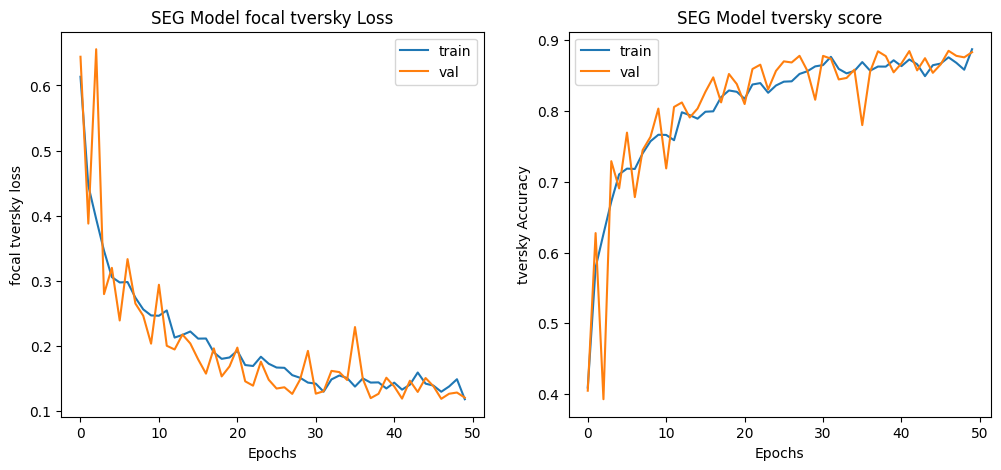

In [31]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title("SEG Model focal tversky Loss")
plt.ylabel("focal tversky loss")
plt.xlabel("Epochs")
plt.legend(['train', 'val'])

plt.subplot(1, 2, 2)
plt.plot(history['tversky'])
plt.plot(history['val_tversky'])
plt.title("SEG Model tversky score")
plt.ylabel("tversky Accuracy")
plt.xlabel("Epochs")
plt.legend(['train', 'val'])
plt.show()

In [32]:
test_ids = list(X_test.image_path)
test_mask = list(X_test.mask_path)

## Segmentation Model Performance

In [33]:
def prediction(test_df, model):
    model.eval()

    # empty lists to store results
    mask, image_id, has_mask = [], [], []

    with torch.no_grad():
        # iterating through each image in the test data
        for i in test_df.image_path:
            img = io.imread(i)
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
            img = np.array(img, dtype=np.float64)

            # standardising the image
            img = (img - img.mean()) / (img.std() + 1e-8)

            X = torch.from_numpy(img.transpose(2, 0, 1)).float().unsqueeze(0).to(device)

            # make prediction of mask
            predict = model(X).cpu().numpy()  # shape (1, 1, H, W)

            # if sum of predicted mask is 0 then there is no tumour
            if predict.round().astype(int).sum() == 0:
                image_id.append(i)
                has_mask.append(0)
                mask.append('No mask :)')
            else:
                # if the sum of pixel values is more than 0, then there is a tumour
                image_id.append(i)
                has_mask.append(1)
                mask.append(predict)

    return pd.DataFrame({'image_path': image_id, 'predicted_mask': mask, 'has_mask': has_mask})


# making predictions
df_pred = prediction(X_test, model)
df_pred

,image_path,predicted_mask,has_mask
0,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,No mask :),0
1,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,[[[[1.4289060e-05 7.3237916e-06 5.9391164e-06 ...,1
2,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,[[[[1.49103007e-05 7.63571825e-06 6.78022752e-...,1
3,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,No mask :),0
4,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,No mask :),0
...,...,...,...
290,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,[[[[1.4282139e-05 7.3083902e-06 5.8878995e-06 ...,1
291,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,[[[[1.4959339e-05 7.4369027e-06 5.9667932e-06 ...,1
292,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,No mask :),0
293,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,No mask :),0


In [34]:
# merging original and prediction df
df_pred = X_test.merge(df_pred, on='image_path').reset_index(drop=True)
df_pred.head(10)

,patient_id,image_path,mask_path,mask,predicted_mask,has_mask
0,TCGA_CS_6667_20011105,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0,No mask :),0
1,TCGA_DU_6405_19851005,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,1,[[[[1.4289060e-05 7.3237916e-06 5.9391164e-06 ...,1
2,TCGA_DU_6407_19860514,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,1,[[[[1.49103007e-05 7.63571825e-06 6.78022752e-...,1
3,TCGA_CS_6668_20011025,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0,No mask :),0
4,TCGA_HT_7882_19970125,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0,No mask :),0
5,TCGA_DU_7010_19860307,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0,No mask :),0
6,TCGA_CS_6666_20011109,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,1,[[[[1.4272732e-05 7.3108104e-06 5.9016643e-06 ...,1
7,TCGA_FG_A4MU_20030903,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0,No mask :),0
8,TCGA_DU_6400_19830518,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0,No mask :),0
9,TCGA_DU_8165_19970205,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0,No mask :),0


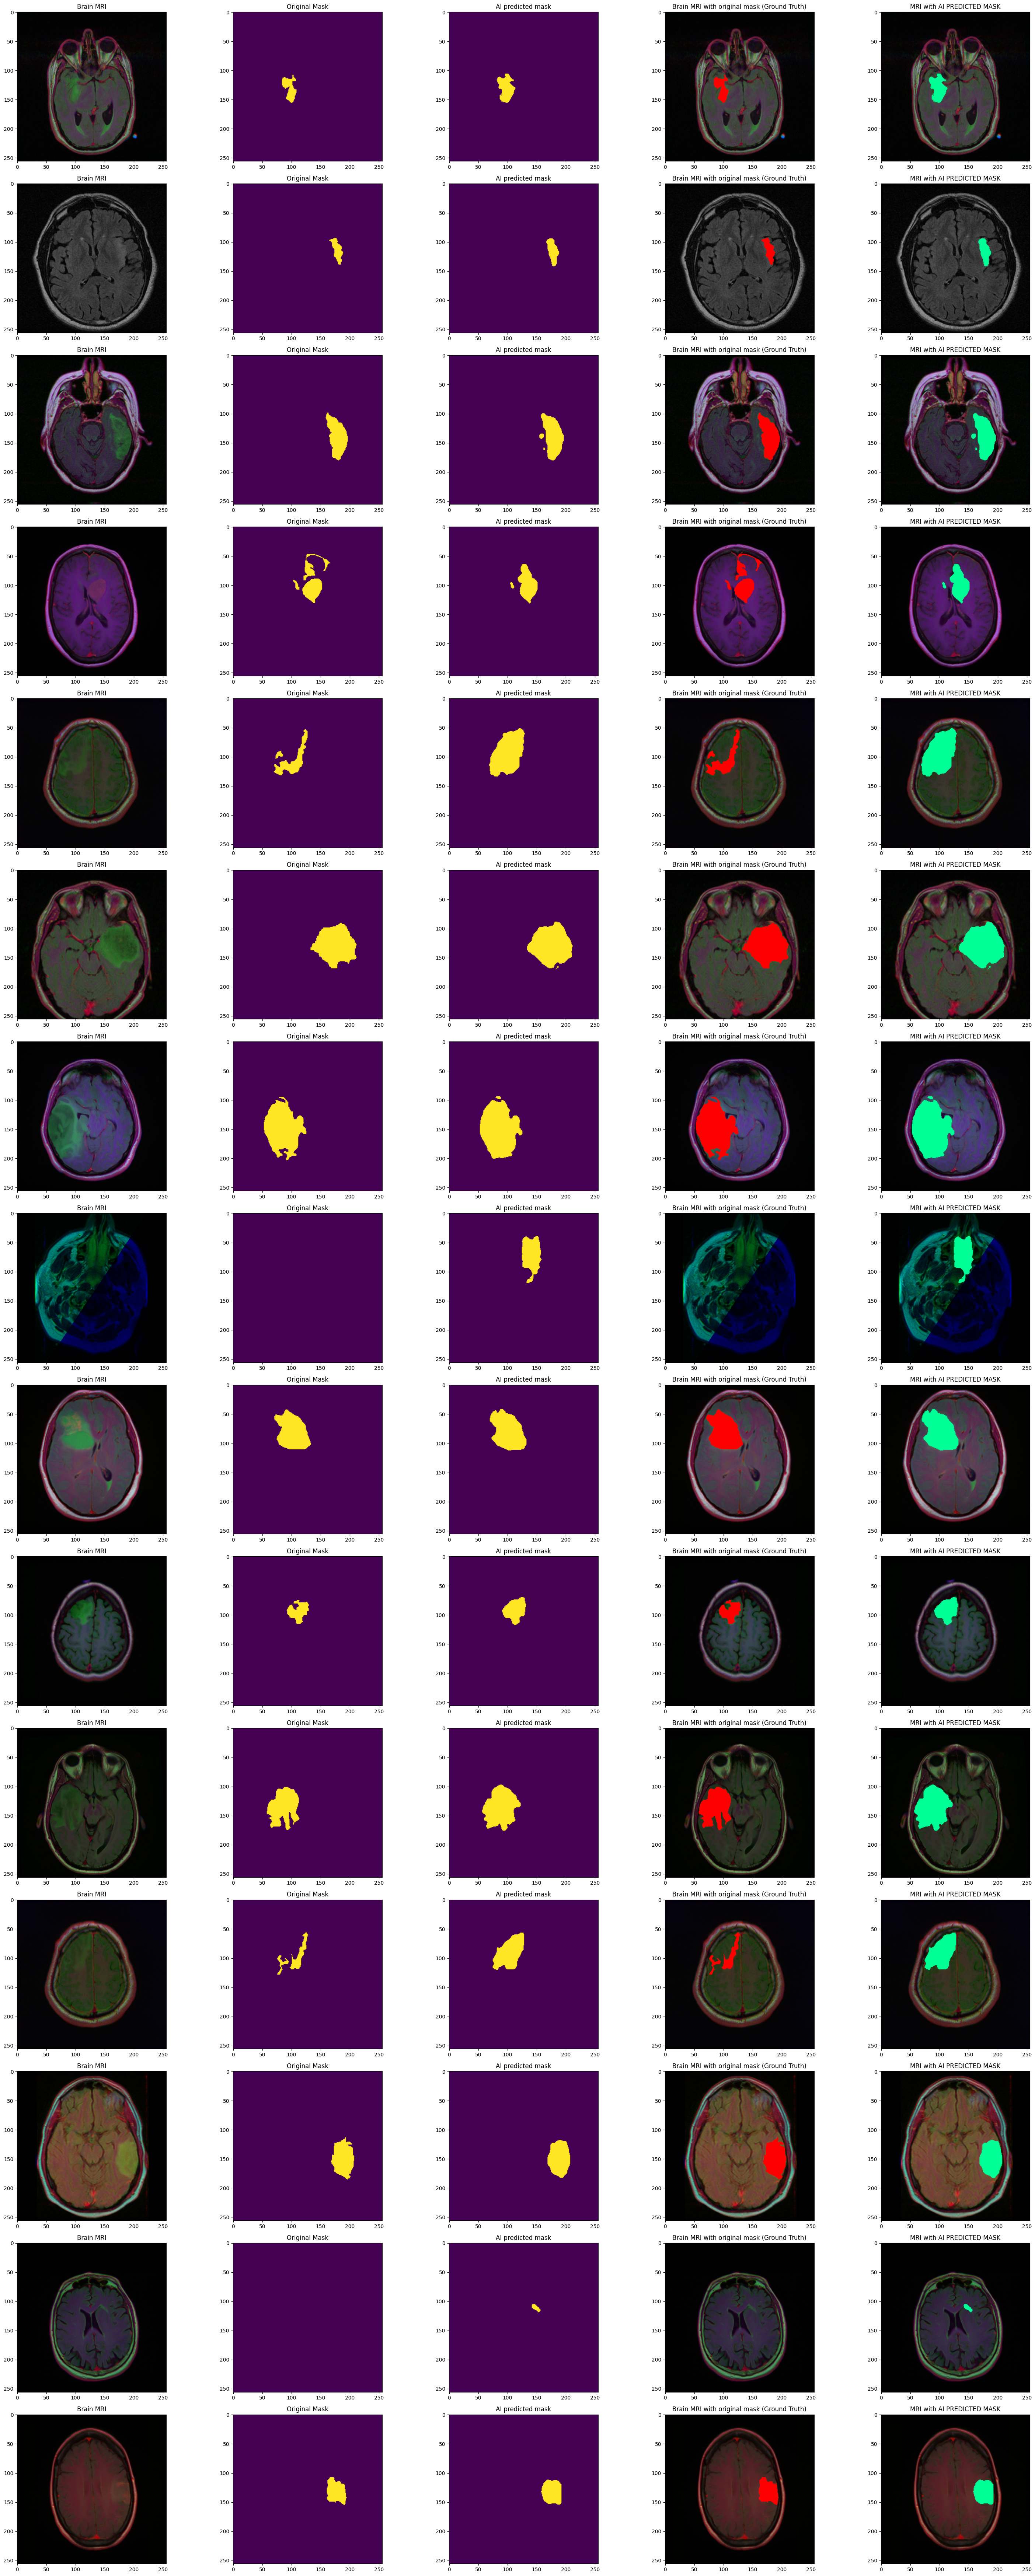

In [35]:
# visualizing predictions
count = 0
fig, axs = plt.subplots(15, 5, figsize=(30, 70))

for i in range(len(df_pred)):
    if df_pred.has_mask[i] == 1 and count < 15:
        # read mri image
        img = io.imread(df_pred.image_path[i])
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        axs[count][0].imshow(img)
        axs[count][0].title.set_text('Brain MRI')

        # read original mask
        mask = io.imread(df_pred.mask_path[i])
        axs[count][1].imshow(mask)
        axs[count][1].title.set_text('Original Mask')

        # read predicted mask
        pred = np.array(df_pred.predicted_mask[i]).squeeze().round()
        axs[count][2].imshow(pred)
        axs[count][2].title.set_text('AI predicted mask')

        # overlay original mask with MRI
        img[mask == 255] = (255, 0, 0)
        axs[count][3].imshow(img)
        axs[count][3].title.set_text('Brain MRI with original mask (Ground Truth)')

        # overlay predicted mask and MRI
        img_ = io.imread(df_pred.image_path[i])
        img_ = cv2.cvtColor(img_, cv2.COLOR_BGR2RGB)
        img_[pred == 1] = (0, 255, 150)
        axs[count][4].imshow(img_)
        axs[count][4].title.set_text('MRI with AI PREDICTED MASK')

        count += 1
    if count == 15:
        break

fig.tight_layout()

## Quantitative Evaluation (Dice, IoU, Pixel Accuracy, Precision/Recall)

Plain pixel accuracy is misleading here because the tumor region is a small fraction of each slice (a model that predicts "no tumor" everywhere would still score 90%+ pixel accuracy). The metrics below are the standard ones for segmentation: **Dice coefficient** and **IoU** measure mask overlap, while precision/recall on the tumor class show whether the model is missing tumors (low recall) or over-predicting them (low precision). Pixel accuracy is included too, only to make the imbalance problem visible by comparison.

This section is framework-agnostic (plain NumPy over the predictions already computed above), so it's unchanged from the original.

In [36]:
def dice_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = y_true.flatten().astype(np.float64)
    y_pred_f = y_pred.flatten().astype(np.float64)
    intersection = np.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (np.sum(y_true_f) + np.sum(y_pred_f) + smooth)

def iou_coef(y_true, y_pred, smooth=1e-6):
    y_true_f = y_true.flatten().astype(np.float64)
    y_pred_f = y_pred.flatten().astype(np.float64)
    intersection = np.sum(y_true_f * y_pred_f)
    union = np.sum(y_true_f) + np.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def pixel_accuracy(y_true, y_pred):
    return np.mean(y_true.flatten() == y_pred.flatten())

def precision_recall(y_true, y_pred, eps=1e-6):
    y_true_f = y_true.flatten().astype(np.float64)
    y_pred_f = y_pred.flatten().astype(np.float64)
    tp = np.sum(y_true_f * y_pred_f)
    fp = np.sum((1 - y_true_f) * y_pred_f)
    fn = np.sum(y_true_f * (1 - y_pred_f))
    precision = (tp + eps) / (tp + fp + eps)
    recall = (tp + eps) / (tp + fn + eps)
    return precision, recall

In [37]:
# Compute metrics for every test image using the predictions already stored in df_pred
results = []

for i in range(len(df_pred)):
    # ground truth mask, resized to match model output and binarized (0/255 -> 0/1)
    gt = io.imread(df_pred.mask_path[i])
    gt = cv2.resize(gt, (256, 256))
    gt = (gt > 0).astype(np.uint8)

    if df_pred.has_mask[i] == 1:
        # predicted_mask is the raw sigmoid output (1,1,256,256) -> binarize
        pred = np.array(df_pred.predicted_mask[i]).squeeze()
        pred = (pred.round()).astype(np.uint8)
    else:
        # model predicted an empty mask
        pred = np.zeros((256, 256), dtype=np.uint8)

    dice = dice_coef(gt, pred)
    iou = iou_coef(gt, pred)
    pix_acc = pixel_accuracy(gt, pred)
    precision, recall = precision_recall(gt, pred)

    results.append({
        "image_path": df_pred.image_path[i],
        "dice": dice,
        "iou": iou,
        "pixel_accuracy": pix_acc,
        "precision": precision,
        "recall": recall
    })

metrics_df = pd.DataFrame(results)
metrics_df.head(10)

,image_path,dice,iou,pixel_accuracy,precision,recall
0,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,1.000000,1.000000,1.000000,1.000000,1.000000
1,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0.789700,0.652482,0.994766,0.659161,0.984709
2,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0.852632,0.743119,0.997437,0.780096,0.940039
3,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,1.000000,1.000000,1.000000,1.000000,1.000000
4,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,1.000000,1.000000,1.000000,1.000000,1.000000
5,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,1.000000,1.000000,1.000000,1.000000,1.000000
6,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,0.929718,0.868667,0.995926,0.882559,0.982202
7,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,1.000000,1.000000,1.000000,1.000000,1.000000
8,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,1.000000,1.000000,1.000000,1.000000,1.000000
9,/kaggle/input/lgg-mri-segmentation/kaggle_3m/T...,1.000000,1.000000,1.000000,1.000000,1.000000


In [38]:
# Summary: mean +/- std across the test set -- this is your real comparable "accuracy" number
summary = metrics_df[["dice", "iou", "pixel_accuracy", "precision", "recall"]].agg(["mean", "std"])
print("Test set segmentation performance (SegFormer-UNet, PyTorch):")
print(summary)

print(f"\nMean Dice coefficient: {metrics_df['dice'].mean():.4f}")
print(f"Mean IoU:              {metrics_df['iou'].mean():.4f}")
print(f"Mean pixel accuracy:   {metrics_df['pixel_accuracy'].mean():.4f}  <- inflated by class imbalance, not the number to trust")
print(f"Mean precision:        {metrics_df['precision'].mean():.4f}")
print(f"Mean recall:           {metrics_df['recall'].mean():.4f}")

Test set segmentation performance (SegFormer-UNet, PyTorch):
          dice       iou  pixel_accuracy  precision    recall
mean  0.885518  0.855812        0.997131   0.900403  0.950056
std   0.257295  0.270327        0.005434   0.216679  0.179430

Mean Dice coefficient: 0.8855
Mean IoU:              0.8558
Mean pixel accuracy:   0.9971  <- inflated by class imbalance, not the number to trust
Mean precision:        0.9004
Mean recall:           0.9501


**How to read this:**
- `Mean Dice` and `Mean IoU` are the numbers to report as "model accuracy" and to compare across runs (baseline vs. modified models) — use these in your ablation table.
- `Mean pixel accuracy` is shown only to demonstrate why it's misleading here — expect it to look artificially high.
- If `precision` is much lower than `recall`, the model is over-predicting tumor regions (false positives). If `recall` is much lower than `precision`, it's missing real tumor regions (false negatives) — useful for deciding which knob to turn next (e.g. Focal Tversky alpha, or `BOUNDARY_WEIGHT`).